In [2]:
import numpy as np
k_b = 1.380649*10**(-23) # J/K
Avrogrado = 6.02214076*10**(23) #1/mol
j_mol = 1*10**3 #J/mol
print(f"{j_mol/Avrogrado/k_b} K")


120.27235504272603 K


In [3]:
# LJ-parameters (eps [K], sigma [A]) per element uit het RASPA .def-bestand
ff_path = "../data/force_field/generic_dreiding_uff_mixing_rules.def"
framework_elements = ["O_", "C_", "H_", "Zn_"]

lj_params = {}  # symbool zoals in de CIF -> (eps, sigma)
with open(ff_path) as f:
    for line in f:
        parts = line.split()
        if parts and parts[0] in framework_elements:
            symbol = parts[0].rstrip("_")
            lj_params[symbol] = (float(parts[2]), float(parts[3]))

lj_params["CH4"] = (158.5, 3.72)  
print(lj_params)

# Lorentz-Berthelot: per roosterelement het paar met CH4
def lorentz_berthelot(p1, p2):
    eps_1, sigma_1 = p1
    eps_2, sigma_2 = p2
    return ((eps_1 * eps_2) ** 0.5, (sigma_1 + sigma_2) / 2)

pair_params = {}  # roostersymbool -> (eps_ij, sigma_ij) voor het paar CH4-symbool
for symbol in framework_elements:
    symbol = symbol.rstrip("_")
    pair_params[symbol] = lorentz_berthelot(lj_params["CH4"], lj_params[symbol])
    print(f"CH4-{symbol}: eps = {pair_params[symbol][0]:.3f} K, sigma = {pair_params[symbol][1]:.4f} A")


{'O': (48.1581, 3.03315), 'C': (47.8562, 3.47299), 'H': (7.64893, 2.84642), 'Zn': (62.3992, 2.46155), 'CH4': (158.5, 3.72)}
CH4-O: eps = 87.367 K, sigma = 3.3766 A
CH4-C: eps = 87.093 K, sigma = 3.5965 A
CH4-H: eps = 34.819 K, sigma = 3.2832 A
CH4-Zn: eps = 99.450 K, sigma = 3.0908 A


In [4]:
import ase.io
import ase
import numpy as np
file_path= "/Users/kasperhuysentruyt/Documents/leven /Cusp/cusp-mlff-gcmc/data/IRMOF-1.cif"
atoms = ase.io.read(file_path, format="cif")

def framework_types(file_path):
    atoms = ase.io.read(file_path, format="cif")
    symbols = atoms.get_chemical_symbols()
    return symbols

framework_types(file_path)
symbols = framework_types(file_path)


/Users/kasperhuysentruyt/Documents/leven /Cusp/cusp-mlff-gcmc/.venv/lib/python3.14/site-packages/ase/io/cif.py:411: UserWarning: crystal system 'cubic' is not interpreted for space group Spacegroup(225, setting=1). This may result in wrong setting!
  warnings.warn(


In [15]:
#distances between CH4 and framework atoms:
positions = atoms.get_positions()
def distances_to_framework(positions, ch4_position,L):
    delta = positions - ch4_position
    distances = np.abs(delta - np.round(delta / L)*L)
    distances = np.linalg.norm(distances, axis=1)    
    return distances

distance_0 = distances_to_framework(positions, np.array([0.0, 0.0, 0.0]), L=atoms.cell[0, 0])
#print(f"distance_0: {distance_0}")
cutoff_distance = 12.0  # Angstrom

#check
if atoms.cell[0, 0]* np.sqrt(3)/2 < distance_0.max():
    print(f"Warning: The cutoff distance is larger than half the box length. This may lead to incorrect results.")

eps_i = [lj_params[s][0] for s in symbols if s in lj_params]
sigma_i = [lj_params[s][1] for s in symbols if s in lj_params]
#print(f"eps_i: {eps_i}")
#print(f"sigma_i: {sigma_i}")
#print(np.unique(eps_i, return_counts=True))
#print(np.unique(sigma_i, return_counts=True))


lorentz_berthelot_params = [lorentz_berthelot((158.5, 3.72), (eps, sigma)) for eps, sigma in zip(eps_i, sigma_i)]
#print(f"lorentz_berthelot_params: {lorentz_berthelot_params}")


lorentz_berthelot_params: [(99.44985268968476, 3.090775), (99.44985268968476, 3.090775), (99.44985268968476, 3.090775), (99.44985268968476, 3.090775), (99.44985268968476, 3.090775), (99.44985268968476, 3.090775), (99.44985268968476, 3.090775), (99.44985268968476, 3.090775), (99.44985268968476, 3.090775), (99.44985268968476, 3.090775), (99.44985268968476, 3.090775), (99.44985268968476, 3.090775), (99.44985268968476, 3.090775), (99.44985268968476, 3.090775), (99.44985268968476, 3.090775), (99.44985268968476, 3.090775), (99.44985268968476, 3.090775), (99.44985268968476, 3.090775), (99.44985268968476, 3.090775), (99.44985268968476, 3.090775), (99.44985268968476, 3.090775), (99.44985268968476, 3.090775), (99.44985268968476, 3.090775), (99.44985268968476, 3.090775), (99.44985268968476, 3.090775), (99.44985268968476, 3.090775), (99.44985268968476, 3.090775), (99.44985268968476, 3.090775), (99.44985268968476, 3.090775), (99.44985268968476, 3.090775), (99.44985268968476, 3.090775), (99.44985268

In [ ]:
#energy calculation
def energy_slow(ch4_position, positions, eps_i, sigma_i, L):
    distances = distances_to_framework(positions, ch4_position, L)
    energy = 0.0
    energy_cutoff = 0.0

    for d, eps, sigma in zip(distances, eps_i, sigma_i):
        lorentz_berthelot_param = lorentz_berthelot((158.5, 3.72), (eps, sigma))
        eps, sigma = lorentz_berthelot_param
        if d < cutoff_distance:
            energy += 4 * eps * ((sigma / d) ** 12 - (sigma / d) ** 6)
            energy_cutoff += 4 * eps * ((sigma / cutoff_distance) ** 12 - (sigma / cutoff_distance) ** 6)
    shifted_energy = energy - energy_cutoff
    return shifted_energy

print(f"Energy at position [0, 0, 0]: {energy_slow(np.array([0.0, 0.0, 0.0]), positions, eps_i, sigma_i, atoms.cell[0, 0])} K")

Energy at position [0, 0, 0]: -117.94958827769321 K


In [94]:
lorentz_berthelot_params = [lorentz_berthelot((158.5, 3.72), (eps, sigma)) for eps, sigma in zip(eps_i, sigma_i)]
eps_pair, sigma_pair = zip(*lorentz_berthelot_params)

def energy_fast(ch4_position, positions, eps_pair, sigma_pair, L):
    
    distances = distances_to_framework(positions, ch4_position, L)
    mask = distances < cutoff_distance
    d = distances[mask]
    eps_pair = np.array(eps_pair)[mask]
    sigma_pair = np.array(sigma_pair)[mask]
    energy = 4 * eps_pair * ((sigma_pair / d) ** 12 - (sigma_pair / d) ** 6)
    energy_cutoff = 4 * eps_pair * ((sigma_pair / cutoff_distance) ** 12 - (sigma_pair / cutoff_distance) ** 6)
    return energy.sum() - energy_cutoff.sum()

print(f"Energy at position [0, 0, 0]: {energy_fast(np.array([0.0, 0.0, 0.0]), positions, eps_pair, sigma_pair, atoms.cell[0, 0])} K")

Energy at position [0, 0, 0]: -117.94958827769332 K


In [75]:
print(f"Energy at position [20, 20, 20]: {energy_fast(np.array([1.0, 1.0, 1.0]), positions, eps_pair, sigma_pair, atoms.cell[0, 0])} K")

Energy at position [20, 20, 20]: -148.57282789222762 K


Fast energies: [np.float64(210324845.38474154), np.float64(180057.47774589807), np.float64(4300842.060632072), np.float64(-1032.3789648383329), np.float64(-183.78602967285707), np.float64(-154.21611295033676), np.float64(-1196.7369337972361), np.float64(6277696838.596651), np.float64(19680159.835297387), np.float64(4355.473189619251), np.float64(-611.8210110054605), np.float64(-292.5563188305011), np.float64(-477.04399191196626), np.float64(610068.8360760057), np.float64(2827366.786464884), np.float64(-771.5713421012051), np.float64(134537393.74422765), np.float64(-646.5752444811778), np.float64(904212.4782190345), np.float64(-703.5778125386084), np.float64(33913442.37661202), np.float64(15651.40322140159), np.float64(-279.33024964065555), np.float64(21570.67037445746), np.float64(3731988.7930562343), np.float64(-452.2924823825225), np.float64(-696.5010387771077), np.float64(3362573.642642242), np.float64(71894270887.15169), np.float64(-448.5904002931024), np.float64(-543.8422799624555

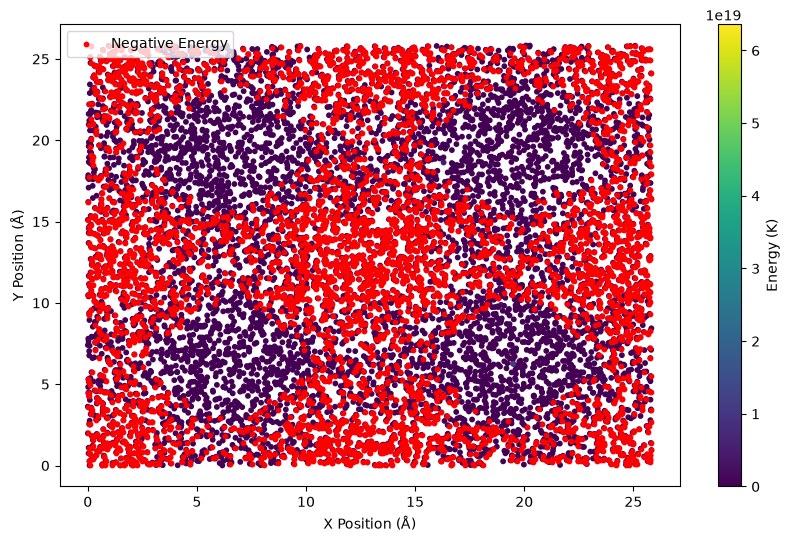

In [ ]:
#plot random positions in the unit cell and their energies
import matplotlib.pyplot as plt
import time
num_samples = 10000
random_positions = np.random.rand(num_samples, 3) * atoms.cell[0, 0]

start_time = time.time()
energies_fast = [energy_fast(pos, positions, eps_pair, sigma_pair, atoms.cell[0, 0]) for pos in random_positions]
fast_time = time.time() - start_time

start_time = time.time()
energies_slow = [energy_slow(pos, positions, eps_i, sigma_i, atoms.cell[0, 0]) for pos in random_positions]
slow_time = time.time() - start_time

print(f"Fast energies: {energies_fast}")
print(f"Slow energies: {energies_slow}")
print(f"Fast time: {fast_time}")
print(f"Slow time: {slow_time}")

plt.figure(figsize=(10, 6))
plt.scatter(random_positions[:, 0], random_positions[:, 1], c=energies_fast, cmap='viridis', s=10)
plt.colorbar(label='Energy (K)')
plt.xlabel('X Position (Å)')
plt.ylabel('Y Position (Å)')
energies=np.array(energies_fast)
mask = energies < 0
fraction_negative = np.count_nonzero(mask)/ len(energies)
print(f"Fraction of negative energies: {fraction_negative:.4f}")
plt.scatter(random_positions[mask, 0], random_positions[mask, 1], c='red', s=10, label='Negative Energy')
plt.legend()

-1038.7939623088937
